楕円曲線ECDH 学習用プログラム（プロット付き）
曲線: y^2 = x^3 + 2x + 2 mod 17
基準点 G = (5, 1)

G の位数 = 19

基準点の倍点表
------------------------------
 1G = (5, 1)
 2G = (6, 3)
 3G = (10, 6)
 4G = (3, 1)
 5G = (9, 16)
 6G = (16, 13)
 7G = (0, 6)
 8G = (13, 7)
 9G = (7, 6)
10G = (7, 11)
11G = (13, 10)
12G = (0, 11)
13G = (16, 4)
14G = (9, 1)
15G = (3, 16)
16G = (10, 11)
17G = (6, 14)
18G = (5, 16)
19G = O

鍵生成
------------------------------
Aliceの秘密鍵: 5
Aliceの公開鍵: (9, 16)

Bobの秘密鍵:   7
Bobの公開鍵:   (0, 6)

ECDH共有鍵計算
------------------------------
Aliceが計算した共有点: (10, 11)
Bobが計算した共有点:   (10, 11)

共有点は一致しました。
共有点 S = (10, 11)


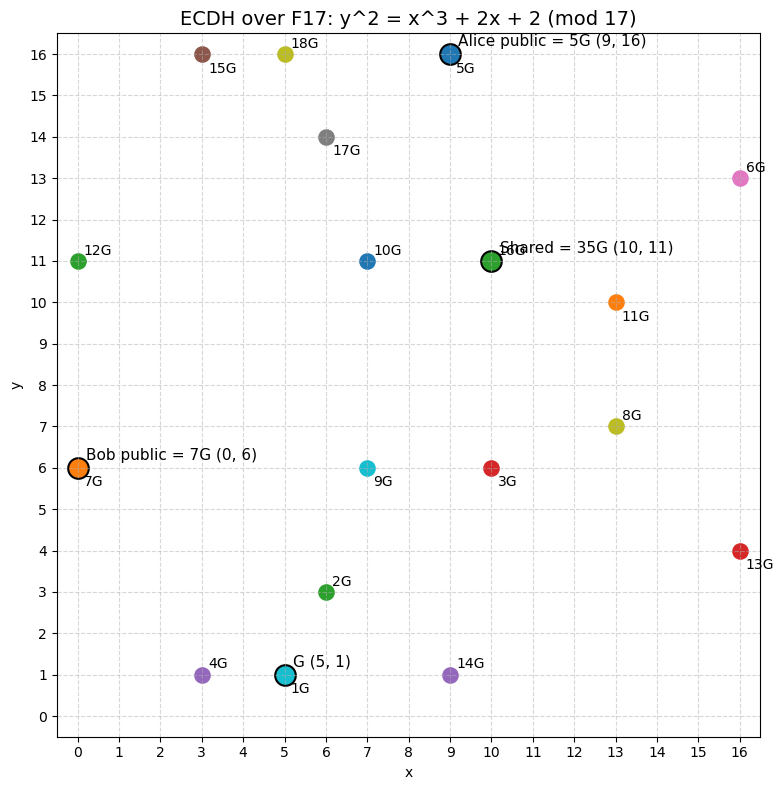

プロット画像を保存しました: ecdh_plot.png


In [1]:
# ============================================================
# 楕円曲線暗号 ECDH の学習用プログラム（プロット付き）
#
# 曲線:
#   y^2 = x^3 + ax + b (mod p)
#
# 使用する値:
#   p = 17
#   a = 2
#   b = 2
#   基準点 G = (5, 1)
#
# Aliceの秘密鍵 = 5
# Bobの秘密鍵   = 7
# ============================================================

from typing import Optional, Tuple, List
import matplotlib.pyplot as plt

# 点を (x, y) で表す
# 無限遠点は None とする
Point = Optional[Tuple[int, int]]

P = 17
A = 2
B = 2

G: Point = (5, 1)


def mod_inverse(value: int, modulus: int) -> int:
    """
    value の modulus における逆元を求める。
    """
    value %= modulus
    if value == 0:
        raise ZeroDivisionError("0の逆元は存在しません。")
    return pow(value, -1, modulus)


def is_on_curve(point: Point) -> bool:
    """
    点が楕円曲線上にあるか確認する。
    無限遠点 None は曲線上の点として扱う。
    """
    if point is None:
        return True

    x, y = point
    left = (y * y) % P
    right = (x * x * x + A * x + B) % P
    return left == right


def point_neg(point: Point) -> Point:
    """
    点の逆元 -P を返す。
    """
    if point is None:
        return None

    x, y = point
    return (x, (-y) % P)


def point_add(point1: Point, point2: Point) -> Point:
    """
    楕円曲線上の2点 point1 と point2 を加算する。
    """

    # 無限遠点 O は加法の単位元
    if point1 is None:
        return point2
    if point2 is None:
        return point1

    x1, y1 = point1
    x2, y2 = point2

    # P + (-P) = O
    if x1 == x2 and (y1 + y2) % P == 0:
        return None

    # 同じ点を加える場合（倍点）
    if point1 == point2:
        numerator = (3 * x1 * x1 + A) % P
        denominator = (2 * y1) % P
    else:
        numerator = (y2 - y1) % P
        denominator = (x2 - x1) % P

    slope = (numerator * mod_inverse(denominator, P)) % P

    x3 = (slope * slope - x1 - x2) % P
    y3 = (slope * (x1 - x3) - y1) % P

    result = (x3, y3)

    if not is_on_curve(result):
        raise ValueError(f"計算結果 {result} は曲線上にありません。")

    return result


def scalar_multiply(k: int, point: Point) -> Point:
    """
    kP を倍加加算法で計算する。
    """
    if k < 0:
        raise ValueError("この例では負の整数倍を扱いません。")

    result: Point = None
    addend = point

    while k > 0:
        if k & 1:
            result = point_add(result, addend)
        addend = point_add(addend, addend)
        k >>= 1

    return result


def curve_points() -> List[Tuple[int, int]]:
    """
    楕円曲線上の全ての有限点を列挙する。
    """
    pts = []
    for x in range(P):
        rhs = (x**3 + A * x + B) % P
        for y in range(P):
            if (y * y) % P == rhs:
                pts.append((x, y))
    return pts


def print_multiple_table(point: Point, maximum: int) -> List[Point]:
    """
    G, 2G, 3G, ... を表示し、その結果リストを返す。
    """
    results = []
    print("基準点の倍点表")
    print("-" * 30)

    for k in range(1, maximum + 1):
        result = scalar_multiply(k, point)
        results.append(result)
        if result is None:
            print(f"{k:2d}G = O")
        else:
            print(f"{k:2d}G = {result}")

    print()
    return results


def point_order(point: Point, max_search: int = 1000) -> int:
    """
    点の位数を求める。
    """
    current = None
    for k in range(1, max_search + 1):
        current = point_add(current, point)
        if current is None:
            return k
    raise ValueError("位数が max_search 以内で見つかりませんでした。")


def plot_curve_and_multiples(
    base_point: Point,
    multiples: List[Point],
    alice_public: Point,
    bob_public: Point,
    shared_point: Point,
    save_path: str = "ecdh_plot.png"
) -> None:
    """
    楕円曲線上の点、倍点、公開鍵、共有点をプロットする。
    """
    all_points = curve_points()

    plt.figure(figsize=(10, 8))

    # 全ての曲線上の点
    xs_all = [pt[0] for pt in all_points]
    ys_all = [pt[1] for pt in all_points]
    plt.scatter(xs_all, ys_all, s=70, alpha=0.35, label="curve points")

    # 倍点をプロット
    plotted_labels = set()
    for i, pt in enumerate(multiples, start=1):
        if pt is None:
            continue
        x, y = pt
        plt.scatter(x, y, s=120)
        label = f"{i}G"
        # 少しずらして注記
        dx = 0.15
        dy = 0.15 if i % 2 == 0 else -0.45
        plt.text(x + dx, y + dy, label, fontsize=10)

    # 特別な点を強調
    special_points = [
        ("G", base_point),
        ("Alice public = 5G", alice_public),
        ("Bob public = 7G", bob_public),
        ("Shared = 35G", shared_point),
    ]

    for name, pt in special_points:
        if pt is not None:
            x, y = pt
            plt.scatter(x, y, s=220, edgecolors="black", linewidths=1.5)
            plt.text(x + 0.2, y + 0.2, f"{name} {pt}", fontsize=11)

    plt.title("ECDH over F17: y^2 = x^3 + 2x + 2 (mod 17)", fontsize=14)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xticks(range(P))
    plt.yticks(range(P))
    plt.xlim(-0.5, P - 0.5)
    plt.ylim(-0.5, P - 0.5)
    plt.grid(True, linestyle="--", alpha=0.5)

    # 格子点が見やすいように正方形にする
    plt.gca().set_aspect("equal", adjustable="box")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

    print(f"プロット画像を保存しました: {save_path}")


def main() -> None:
    print("楕円曲線ECDH 学習用プログラム（プロット付き）")
    print("=" * 50)
    print(f"曲線: y^2 = x^3 + {A}x + {B} mod {P}")
    print(f"基準点 G = {G}")
    print()

    if not is_on_curve(G):
        raise ValueError("基準点Gが曲線上にありません。")

    order = point_order(G)
    print(f"G の位数 = {order}")
    print()

    # 倍点表
    multiples = print_multiple_table(G, order)

    # AliceとBobの秘密鍵
    alice_private = 5
    bob_private = 7

    # 公開鍵
    alice_public = scalar_multiply(alice_private, G)
    bob_public = scalar_multiply(bob_private, G)

    print("鍵生成")
    print("-" * 30)
    print(f"Aliceの秘密鍵: {alice_private}")
    print(f"Aliceの公開鍵: {alice_public}")
    print()
    print(f"Bobの秘密鍵:   {bob_private}")
    print(f"Bobの公開鍵:   {bob_public}")
    print()

    # 共有点を計算
    alice_shared = scalar_multiply(alice_private, bob_public)
    bob_shared = scalar_multiply(bob_private, alice_public)

    print("ECDH共有鍵計算")
    print("-" * 30)
    print(f"Aliceが計算した共有点: {alice_shared}")
    print(f"Bobが計算した共有点:   {bob_shared}")
    print()

    if alice_shared == bob_shared:
        print("共有点は一致しました。")
        print(f"共有点 S = {alice_shared}")
    else:
        print("エラー: 共有点が一致しません。")

    # プロット
    plot_curve_and_multiples(
        base_point=G,
        multiples=multiples[:-1],  # 最後は 19G = O なので除く
        alice_public=alice_public,
        bob_public=bob_public,
        shared_point=alice_shared,
        save_path="ecdh_plot.png"
    )


if __name__ == "__main__":
    main()